# 12 — The level: cohort drift and its repair

Notebook 08 found that completion within 5 years fell from 12.8% for 2017 entrants to 8.3% and 9.6% for 2018 and 2019 entrants, while LightGBM, fitted on entrants to 2016, stayed at 13–14%: a tree cannot extrapolate the request year. For a portfolio the level matters as much as the ranking, because expected MW online scales with it. This notebook asks what drifted (the hazard of operation, of withdrawal, or both), repairs the level of the v2 model with a rolling recalibration that never sees the cohort it scores, reports slope **and** intercept on the 2018–2019 entrants (criterion C7), and holds the models' first- and second-year predictions against the 2020–2022 entrants' outcomes from both editions of the LBNL file.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02/04/06 |
| in | `data/processed/predictions_v2.parquet`, `results/variant_chosen.json` | notebook 11 — the v2 model and both baselines on the test cohort |
| in | `results/early_incidence_2020_2022.csv` | notebook 01b — observed 1- and 2-year incidence of the 2020–2022 entrants, both editions |
| in | `results/success_criteria_v2_registered.json` | notebook 11 — bootstrap settings |
| out | `results/drift_by_cohort.csv`, `results/drift_by_cohort_region.csv`, `results/drift_hazards_by_cohort.csv` | the diagnosis |
| out | `results/recalibration.csv` | the rolling intercepts per scored year and region |
| out | `results/level_repair_metrics.csv` | slope and intercept with intervals, per option and cohort (C7's inputs) |
| out | `results/early_hazards_2020_2022.csv` | predicted against observed P(operation by 1 and 2 years), 2020–2022 entrants |
| out | `data/processed/predictions_v2_recalibrated.parquet` | the v2 model's raw and recalibrated test predictions |
| out | `figures/F11_level_by_entry_year.*`, `figures/12_level_repair/*` | F11 and the notebook's figures |
| out | `results/level_checks.csv` | this notebook's checks |

## Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, evaluation, paths, plots, survival_tools, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "12_level_repair"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 100
LEVEL_HORIZONS = [3, 5]  # the horizons C7 names; 7 years is observed for 2017 entrants only
SOURCE_YEAR = {2017: 2016, 2018: 2017, 2019: 2018}  # each scored cohort takes its level from the cohort before it
TEST_YEARS = list(SOURCE_YEAR)


def save(fig, name, caption):
    """Save a figure of this notebook under figures/12_level_repair/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"

## 1. Data and the v2 model

The v2 model is the candidate notebook 11 chose on 2016 entrants (`results/variant_chosen.json`), refitted here twice: on entrants to 2015, to predict the 2016 cohort out of sample (the level source for 2017), and on entrants to 2016, to predict 2017–2019 as notebook 11 did (the refit is checked against notebook 11's stored predictions).

In [2]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
CHOSEN = json.loads((paths.RESULTS / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
SPEC = variants.CANDIDATES[CHOSEN]
pred_v2 = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet")

tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
cohort_2016 = track_a[track_a["q_year"] == config.VALIDATION_YEAR].copy()
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = variants.at_least_20(test)
cohort_2016["large"] = variants.at_least_20(cohort_2016)

fit_tune = variants.fit_candidate(SPEC, tune, clean, tuning)
fit_final = variants.fit_candidate(SPEC, final, clean, tuning)
p_2016 = discrete_time.predict_both(fit_tune, cohort_2016)[SPEC["model"]]
p_test = discrete_time.predict_both(fit_final, test)[SPEC["model"]]
stored = {h: pred_v2[pred_v2["horizon"] == h].set_index("project_key").loc[test["project_key"].astype(str), "chosen"].to_numpy()
          for h in config.HORIZONS}
refit_gap = max(float(np.abs(p_test[h].to_numpy() - stored[h]).max()) for h in config.HORIZONS)
assert refit_gap < 1e-6, f"the refit differs from notebook 11's stored predictions by {refit_gap}"
LOGIT = "K1 logit, entry congestion"  # option (a): the logit's linear request-year term extrapolates
print(f"v2 model: {CHOSEN}; refit matches notebook 11 (max gap {refit_gap:.1e}); {(time.time() - START) / 60:.1f} min")

v2 model: K0 LightGBM, yearly congestion; refit matches notebook 11 (max gap 0.0e+00); 0.2 min


## 2. What drifted

**2a. The level by entry year.** Observed P(operation by 3 and 5 years) of each test entry year with a bootstrap band, against the mean prediction of the v1 baseline, the fair baseline, the v1 LightGBM, the v2 model and the K1 logit, for all test requests and for the ≥ 20 MW cohort.

In [3]:
durations, events = test["duration_years"].to_numpy(), test["event"].to_numpy()
years, regions = test["q_year"].to_numpy(), test["region"].astype(str).to_numpy()
V1 = "K0 LightGBM, yearly congestion"  # notebook 06's model, stored by notebook 11 under its candidate name
MODELS = {"baseline": "baseline", "fair_baseline": "fair_baseline", "v1 LightGBM": V1, "v2": "chosen", LOGIT: LOGIT}
preds = {h: {label: pred_v2[pred_v2["horizon"] == h].set_index("project_key").loc[test["project_key"].astype(str), column].to_numpy()
             for label, column in MODELS.items()} for h in config.HORIZONS}
rows = []
for cohort, mask in [("all", np.ones(len(test), bool)), ("≥ 20 MW", test["large"].to_numpy())]:
    for h in LEVEL_HORIZONS:
        t = drift.level_by_group({m: p[mask] for m, p in preds[h].items()}, durations[mask], events[mask], years[mask], h,
                                 n_boot=N_BOOT, seed=SEED + h)
        t.insert(0, "horizon", h)
        t.insert(0, "cohort", cohort)
        rows.append(t.rename(columns={"group": "entry_year"}))
by_year = pd.concat(rows, ignore_index=True).sort_values(["cohort", "horizon", "entry_year"])
by_year.to_csv(paths.RESULTS / "drift_by_cohort.csv", index=False)
by_region = []
for h in LEVEL_HORIZONS:
    for region in TRACK_A:
        mask = regions == region
        t = drift.level_by_group({m: p[mask] for m, p in preds[h].items()}, durations[mask], events[mask], years[mask], h,
                                 n_boot=N_BOOT, seed=SEED + 50 + h)
        t.insert(0, "horizon", h)
        t.insert(0, "region", region)
        by_region.append(t.rename(columns={"group": "entry_year"}))
by_region = pd.concat(by_region, ignore_index=True).sort_values(["horizon", "region", "entry_year"])
by_region.to_csv(paths.RESULTS / "drift_by_cohort_region.csv", index=False)
by_year.round(3)

,cohort,horizon,entry_year,n,observed,low,high,baseline,fair_baseline,v1 LightGBM,v2,"K1 logit, entry congestion"
0,all,3,2017,549,0.053,0.033,0.073,0.087,0.090,0.073,0.073,0.069
1,all,3,2018,672,0.049,0.033,0.064,0.086,0.081,0.061,0.061,0.049
2,all,3,2019,1047,0.053,0.040,0.070,0.083,0.081,0.070,0.070,0.056
3,all,5,2017,549,0.128,0.102,0.157,0.150,0.154,0.142,0.142,0.144
4,all,5,2018,672,0.083,0.061,0.103,0.146,0.143,0.131,0.131,0.116
5,all,5,2019,1047,0.096,0.080,0.113,0.141,0.138,0.136,0.136,0.120
6,≥ 20 MW,3,2017,428,0.033,0.014,0.047,0.075,0.065,0.048,0.048,0.038
7,≥ 20 MW,3,2018,556,0.025,0.013,0.041,0.083,0.069,0.044,0.044,0.034
8,≥ 20 MW,3,2019,855,0.015,0.009,0.023,0.077,0.065,0.051,0.051,0.038
9,≥ 20 MW,5,2017,428,0.110,0.079,0.138,0.137,0.132,0.123,0.123,0.115


**Reading this.** The drift is in the primary cohort too, and it is monotone. Among requests of 20 MW and more, observed completion within 5 years fell from 11.0% for 2017 entrants to 5.9% and 6.1% for 2018 and 2019 entrants, and within 3 years from 3.3% to 2.5% and 1.5%; the v2 model (the v1 LightGBM) stayed at 12.3%, 11.8% and 12.2% at 5 years and 4.4–5.1% at 3 years. The fair baseline sits higher still (13.2%, 13.3%, 12.4%) and the logit's linear trend lower (11.5%, 10.4%, 10.6%) but not low enough. Every model, baseline included, is calibrated to a world that ended with the training years.

**2b. Which hazard moved.** The yearly hazards of operation and of withdrawal in the first three years in the queue, by entry cohort 2012–2019 (project-years from `discrete_time.observed_years`, as the models see them). If the operation hazard fell while the withdrawal hazard held, the drift is in how fast projects get built; if withdrawals rose, in how many survive to be built.

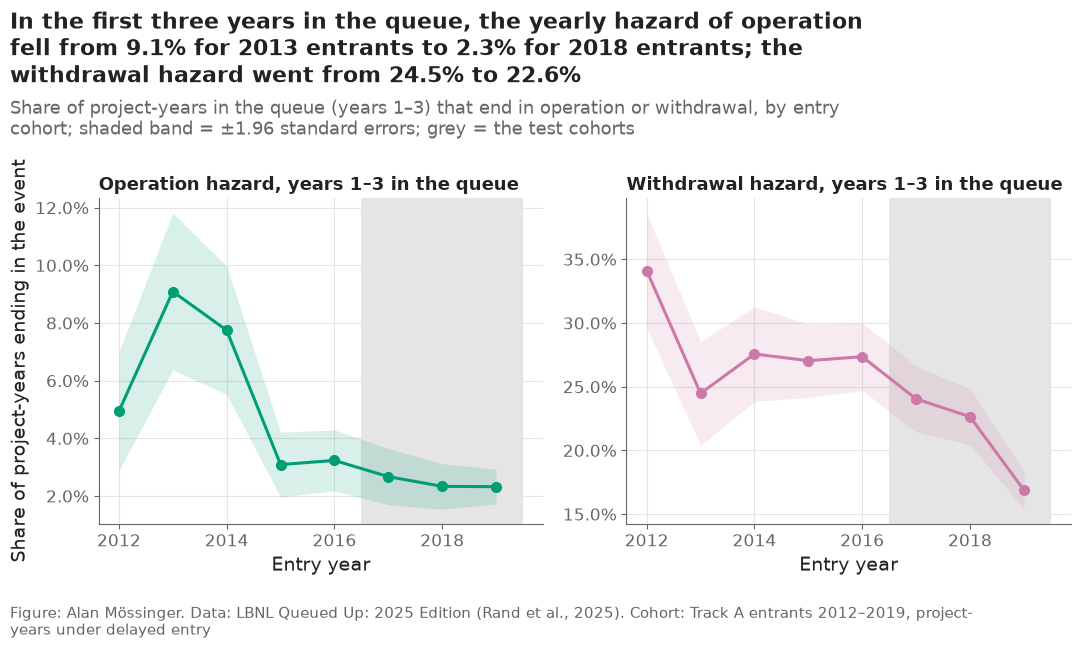

,q_year,project_years,h_operation,h_withdrawal,se_operation,se_withdrawal
0,2012,425,0.0494,0.3412,0.0105,0.0230
1,2013,429,0.0909,0.2448,0.0139,0.0208
2,2014,555,0.0775,0.2757,0.0113,0.0190
3,2015,906,0.0309,0.2704,0.0057,0.0148
4,2016,1082,0.0323,0.2736,0.0054,0.0136
5,2017,1048,0.0267,0.2405,0.0050,0.0132
6,2018,1413,0.0234,0.2265,0.0040,0.0111
7,2019,2409,0.0232,0.1689,0.0031,0.0076


In [4]:
cohorts = track_a[track_a["q_year"].between(2012, 2019)]
rows_c = discrete_time.observed_years(cohorts)
rows_c["q_year"] = cohorts.loc[rows_c["project"], "q_year"].to_numpy()
early = rows_c[rows_c["year_in_queue"] <= 3]
haz = (early.groupby("q_year")["outcome"].agg(project_years="size", h_operation=lambda s: (s == 1).mean(),
                                               h_withdrawal=lambda s: (s == 2).mean()).reset_index())
haz["se_operation"] = np.sqrt(haz["h_operation"] * (1 - haz["h_operation"]) / haz["project_years"])
haz["se_withdrawal"] = np.sqrt(haz["h_withdrawal"] * (1 - haz["h_withdrawal"]) / haz["project_years"])
haz.to_csv(paths.RESULTS / "drift_hazards_by_cohort.csv", index=False)

fig, axes = plt.subplots(1, 2)
for ax, cause, color in zip(axes, ["operation", "withdrawal"], [config.OUTCOME_COLORS["operation"], config.OUTCOME_COLORS["withdrawal"]]):
    h, se = haz[f"h_{cause}"], haz[f"se_{cause}"]
    ax.fill_between(haz["q_year"], (h - 1.96 * se).clip(lower=0), h + 1.96 * se, color=color, alpha=0.15, linewidth=0)
    ax.plot(haz["q_year"], h, color=color, marker="o")
    ax.axvspan(2016.5, 2019.5, color="#E5E5E5", zorder=0)
    ax.set_xlabel("Entry year")
    ax.set_title(f"{cause.capitalize()} hazard, years 1–3 in the queue", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_ylabel("Share of project-years ending in the event")
h_op = haz.set_index("q_year")["h_operation"]
h_wd = haz.set_index("q_year")["h_withdrawal"]
plots.finish(fig,
             f"In the first three years in the queue, the yearly hazard of operation fell from {h_op.loc[2013]:.1%} for 2013 entrants "
             f"to {h_op.loc[2018]:.1%} for 2018 entrants; the withdrawal hazard went from {h_wd.loc[2013]:.1%} to {h_wd.loc[2018]:.1%}",
             "Share of project-years in the queue (years 1–3) that end in operation or withdrawal, by entry cohort; "
             "shaded band = ±1.96 standard errors; grey = the test cohorts",
             "Track A entrants 2012–2019, project-years under delayed entry")
save(fig, "12_01_hazards_by_cohort", "Early-year hazards of operation and withdrawal by entry cohort, 2012–2019.")
plt.show()
haz.round(4)

**Reading this.** It is the hazard of being built that collapsed, not the hazard of leaving. In the first three years in the queue, the yearly hazard of operation was 9.1% for 2013 entrants, 7.8% for 2014, then 3.1% from 2015 and 2.3% by 2018–2019 — a fall of three quarters in six cohorts. The withdrawal hazard moved less (24–34% through 2016, 23% for 2018, 17% for 2019): projects are not leaving faster, they are waiting longer. A model fitted on entrants to 2016 therefore learned early-year operation hazards two to three times those of the cohorts it is asked to score, which is exactly the over-prediction of table 2a.

## 3. Repairing the level

**Option (a), a trend term.** The discrete-time logit already carries the request year as a number, so its level extrapolates linearly; its line in table 2a shows what that buys.

**Option (b), rolling recalibration.** The v2 model keeps its ranking and gets its level from the newest resolved cohort before the one being scored: 2017 entrants from the 2016 cohort (predicted out of sample by the fit on entrants to 2015), 2018 from 2017, 2019 from 2018; an intercept per region and horizon, pooled when a region has fewer than 30 weighted source requests (`src/drift.rolling_recalibration`). The scored cohort's own outcomes never enter its intercept. The source cohort's outcomes have to be observed by the analysis date, so this is the level an analyst sets today from the newest cohort that has had time to resolve — not a level knowable on the request date; the report says so.

**Option (c), a Bayesian random walk on the cohort intercept** (PyMC), is a stretch item (decision #46) and is not fitted here.

In [5]:
pool = pd.concat([cohort_2016, test])
pool_years = pool["q_year"].to_numpy()
pool_regions = pool["region"].astype(str).to_numpy()
pool_d, pool_e = pool["duration_years"].to_numpy(), pool["event"].to_numpy()
pool_follow = ((pd.Timestamp(config.CENSOR_DATE) - pool["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
G_pool = evaluation.censoring_km(pool_follow, np.ones(len(pool), bool))
raw = {h: np.concatenate([p_2016[h].to_numpy(), p_test[h].to_numpy()]) for h in LEVEL_HORIZONS}
recal, intercepts = {}, []
for h in LEVEL_HORIZONS:
    y, w = evaluation.horizon_outcome(pool_d, pool_e, h, G_pool)
    out, table = drift.rolling_recalibration(raw[h], y, w, pool_years, pool_regions, SOURCE_YEAR)
    recal[h] = out[len(cohort_2016):]  # the test rows
    intercepts.append(table.assign(horizon=h))
intercepts = pd.concat(intercepts, ignore_index=True)
intercepts.to_csv(paths.RESULTS / "recalibration.csv", index=False)
print("mean predicted P(operation by 5 years), test cohort: raw "
      f"{preds[5]['v2'].mean():.1%} → recalibrated {np.nanmean(recal[5]):.1%}; observed {survival_tools.aalen_johansen(durations, events, [5])['cif_operation'].iloc[0]:.1%}")
intercepts.pivot_table(index=["horizon", "scored_year"], columns="region", values="intercept").round(2)

mean predicted P(operation by 5 years), test cohort: raw 13.6% → recalibrated 11.2%; observed 10.0%


region               CAISO  ERCOT   PJM
horizon scored_year                    
3       2017          0.53   0.04 -0.11
        2018          0.38  -0.23 -0.49
        2019          0.44  -0.15 -0.34
5       2017         -0.72   0.25  0.14
        2018          0.16   0.30 -0.39
        2019         -0.29  -0.23 -0.73

**Reading this.** The intercepts say where the level moved. For the 2019 cohort, scored on the 2018 cohort's outcomes, the 5-year shift is −0.73 in PJM, −0.29 in CAISO and −0.23 in ERCOT on the logit scale; for 2018, scored on 2017, PJM is −0.39 while CAISO (+0.16) and ERCOT (+0.30) go the other way, because the 2017 cohort ran high in those two regions. A rolling rule can only follow the cohort before, so when the level falls year after year it stays one step behind — which the next section measures.

## 4. The level on the 2018–2019 entrants (criterion C7) and figure F11

Calibration slope and intercept, with bootstrap intervals, of each option on the 2018–2019 entrants of 20 MW and more (C7's cohort), and for reference on all 2018–2019 entrants and on the 2017 entrants (whose source cohort, 2016, was predicted out of sample). An intercept shift leaves the ranking untouched *within* a region and entry year; across regions the shifts differ, so Uno's C on a pooled cohort can move a little, and it is reported to show by how much.

In [6]:
OPTIONS = {"v2 raw": lambda h: preds[h]["v2"], "v2 recalibrated": lambda h: recal[h], "K1 logit (trend)": lambda h: preds[h][LOGIT],
           "fair baseline": lambda h: preds[h]["fair_baseline"], "v1 baseline": lambda h: preds[h]["baseline"]}
COHORTS_C7 = {"2018–2019, ≥ 20 MW": (np.isin(years, [2018, 2019]) & test["large"].to_numpy()),
              "2018–2019, all": np.isin(years, [2018, 2019]),
              "2017, ≥ 20 MW": (years == 2017) & test["large"].to_numpy()}
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
rows = []
for c_i, (cohort, mask) in enumerate(COHORTS_C7.items()):
    G = evaluation.censoring_km(follow_up[mask], np.ones(int(mask.sum()), bool))
    for h in LEVEL_HORIZONS:
        sub = {name: f(h)[mask] for name, f in OPTIONS.items()}
        point = evaluation.score_horizon(sub, durations[mask], events[mask], h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask], events[mask], h, G, sw),
                                     int(mask.sum()), N_BOOT, SEED + 200 + 10 * c_i + h)
        t = evaluation.summarise(point, draws, reference="fair baseline", level=LEVEL)
        t.insert(0, "horizon", h)
        t.insert(0, "cohort", cohort)
        rows.append(t)
level_metrics = pd.concat(rows, ignore_index=True)
level_metrics.to_csv(paths.RESULTS / "level_repair_metrics.csv", index=False)
show = level_metrics[level_metrics["metric"].isin(["slope", "intercept", "uno_c"])].copy()
show["value"] = [f"{r.estimate:.2f} [{r.low:.2f}, {r.high:.2f}]" for r in show.itertuples()]
show.pivot_table(index=["cohort", "horizon", "metric"], columns="model", values="value", aggfunc="first")[list(OPTIONS)]

model                                               v2 raw       v2 recalibrated      K1 logit (trend)         fair baseline           v1 baseline
cohort             horizon metric                                                                                                                 
2017, ≥ 20 MW      3       intercept   -0.41 [-1.03, 0.01]   -0.40 [-1.01, 0.01]   -0.17 [-0.79, 0.26]  -0.79 [-1.40, -0.38]  -0.90 [-1.52, -0.50]
                           slope         1.27 [0.88, 1.81]     1.37 [0.93, 1.95]     0.85 [0.26, 1.53]     1.56 [1.07, 2.26]     2.29 [1.22, 3.93]
                           uno_c         0.81 [0.71, 0.89]     0.82 [0.73, 0.89]     0.70 [0.55, 0.85]     0.91 [0.83, 0.97]     0.79 [0.66, 0.93]
                   5       intercept   -0.13 [-0.40, 0.14]   -0.27 [-0.53, 0.01]   -0.05 [-0.34, 0.23]   -0.24 [-0.54, 0.07]  -0.26 [-0.56, -0.00]
                           slope         1.22 [0.86, 1.70]     1.00 [0.63, 1.55]     0.72 [0.36, 1.15]     0.78 [0.17, 1.59]     0.43 [0.06, 2.18]
                           uno_c         0.72 [0.67, 0.78]     0.73 [0.67, 0.78]     0.64 [0.57, 0.71]     0.79 [0.72, 0.85]     0.76 [0.68, 0.83]
2018–2019, all     3       intercept  -0.30 [-0.50, -0.10]    0.01 [-0.20, 0.21]   -0.04 [-0.25, 0.18]  -0.52 [-0.72, -0.32]  -0.53 [-0.74, -0.33]
                           slope         1.50 [1.28, 1.83]     1.50 [1.27, 1.80]     1.15 [0.95, 1.38]     1.54 [1.26, 1.88]     1.57 [1.12, 2.12]
                           uno_c         0.87 [0.83, 0.90]     0.87 [0.83, 0.91]     0.85 [0.81, 0.89]     0.81 [0.76, 0.86]     0.73 [0.67, 0.79]
                   5       intercept  -0.47 [-0.65, -0.33]   -0.08 [-0.27, 0.06]  -0.32 [-0.51, -0.18]  -0.52 [-0.71, -0.39]  -0.52 [-0.71, -0.39]
                           slope         1.41 [1.12, 1.74]     1.21 [0.96, 1.49]     1.14 [0.90, 1.41]     1.31 [1.06, 1.64]     1.53 [1.14, 2.04]
                           uno_c         0.78 [0.73, 0.81]     0.78 [0.74, 0.82]     0.77 [0.72, 0.81]     0.74 [0.69, 0.79]     0.73 [0.68, 0.77]
2018–2019, ≥ 20 MW 3       intercept  -1.01 [-1.44, -0.69]  -0.74 [-1.17, -0.41]  -0.72 [-1.20, -0.41]  -1.35 [-1.80, -1.01]  -1.51 [-1.96, -1.18]
                           slope         1.06 [0.73, 1.44]     1.09 [0.78, 1.43]     0.79 [0.51, 1.10]     0.98 [0.47, 1.43]     0.87 [0.26, 1.59]
                           uno_c         0.76 [0.66, 0.85]     0.78 [0.70, 0.86]     0.77 [0.67, 0.85]     0.71 [0.62, 0.80]     0.65 [0.53, 0.75]
                   5       intercept  -0.81 [-1.01, -0.62]  -0.47 [-0.70, -0.27]  -0.66 [-0.87, -0.46]  -0.88 [-1.10, -0.67]  -0.94 [-1.16, -0.74]
                           slope         1.21 [0.93, 1.60]     1.18 [0.93, 1.54]     1.04 [0.78, 1.39]     1.12 [0.81, 1.49]     1.31 [0.77, 1.89]
                           uno_c         0.73 [0.68, 0.79]     0.77 [0.73, 0.83]     0.76 [0.71, 0.81]     0.73 [0.68, 0.78]     0.75 [0.71, 0.80]

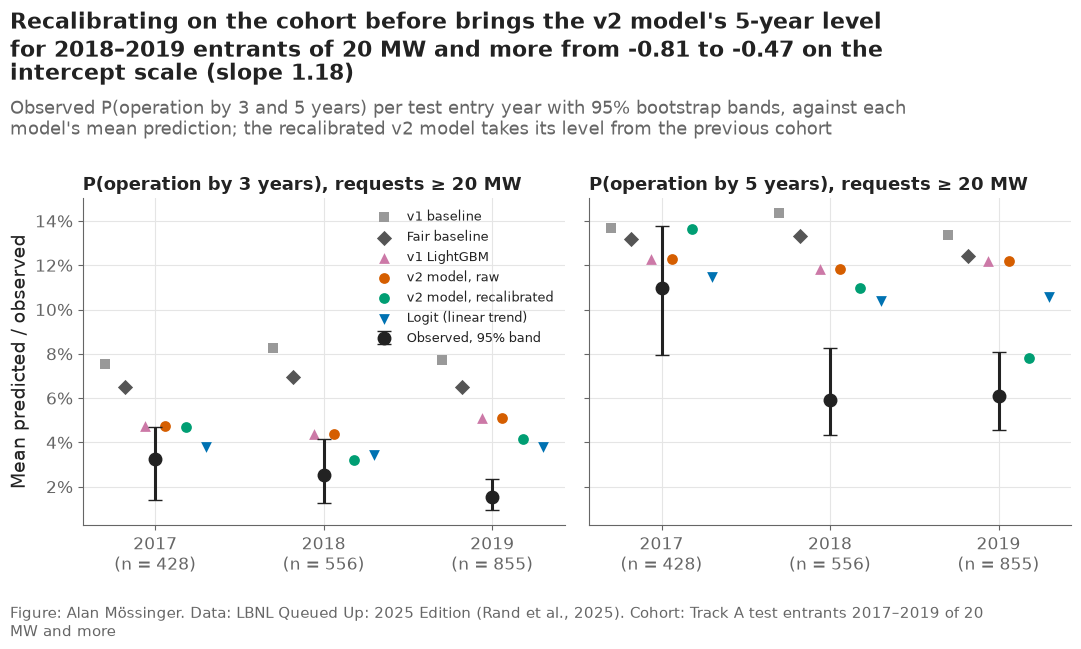

In [7]:
fig, axes = plt.subplots(1, 2, sharey=True)
style = {"baseline": ("#999999", "s"), "fair_baseline": ("#555555", "D"), "v1 LightGBM": ("#CC79A7", "^"),
         "v2": ("#D55E00", "o"), "v2 recalibrated": ("#009E73", "o"), LOGIT: ("#0072B2", "v")}
labels = {"baseline": "v1 baseline", "fair_baseline": "Fair baseline", "v1 LightGBM": "v1 LightGBM", "v2": "v2 model, raw",
          "v2 recalibrated": "v2 model, recalibrated", LOGIT: "Logit (linear trend)"}
offsets = dict(zip(style, np.linspace(-0.3, 0.3, len(style))))
for ax, h in zip(axes, LEVEL_HORIZONS):
    part = by_year[(by_year["cohort"] == "≥ 20 MW") & (by_year["horizon"] == h)].set_index("entry_year").loc[TEST_YEARS]
    x = np.arange(len(TEST_YEARS))
    ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                color=plots.INK, capsize=5, markersize=9, label="Observed, 95% band", zorder=4)
    large = test["large"].to_numpy()
    for m, (color, marker) in style.items():
        if m == "v2 recalibrated":
            values = [np.nanmean(recal[h][(years == y) & large]) for y in TEST_YEARS]
        else:
            values = part[m].to_numpy()
        ax.scatter(x + offsets[m], values, marker=marker, color=color, s=60, zorder=3, label=labels[m])
    ax.set_xticks(x, [f"{y}\n(n = {n:,})" for y, n in zip(TEST_YEARS, part["n"])])
    ax.set_title(f"P(operation by {h} years), requests ≥ 20 MW", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean predicted / observed")
axes[0].legend(loc="upper right", fontsize=9)  # the left panel has room above its points
lm = level_metrics.set_index(["cohort", "horizon", "model", "metric"])["estimate"]
plots.finish(fig,
             f"Recalibrating on the cohort before brings the v2 model's 5-year level for 2018–2019 entrants of 20 MW and more "
             f"from {lm[('2018–2019, ≥ 20 MW', 5, 'v2 raw', 'intercept')]:+.2f} to "
             f"{lm[('2018–2019, ≥ 20 MW', 5, 'v2 recalibrated', 'intercept')]:+.2f} on the intercept scale "
             f"(slope {lm[('2018–2019, ≥ 20 MW', 5, 'v2 recalibrated', 'slope')]:.2f})",
             "Observed P(operation by 3 and 5 years) per test entry year with 95% bootstrap bands, against each model's mean "
             "prediction; the recalibrated v2 model takes its level from the previous cohort",
             "Track A test entrants 2017–2019 of 20 MW and more")
plots.save_fig(fig, "F11_level_by_entry_year",
               "Observed against predicted P(operation by 3 and 5 years) by test entry year for requests of 20 MW and more, "
               "before and after the rolling recalibration.", NOTEBOOK)
plt.show()

**Reading this.** On the C7 cohort (2018–2019 entrants of 20 MW and more) the raw v2 model's intercept is −1.01 [−1.44, −0.69] at 3 years and −0.81 [−1.01, −0.62] at 5 years: its probabilities are too high by a factor of two to three on the odds scale. The rolling recalibration takes the intercepts to −0.74 [−1.17, −0.41] and −0.47 [−0.70, −0.27], removing about 40% of the gap, with slopes of 1.09 and 1.18. No option reaches an intercept interval that covers zero: the logit's trend gives −0.72 and −0.66, the fair baseline −1.35 and −0.88. **Criterion C7 fails for every option**, and the report will say so: the level an analyst can set from the newest resolved cohort is still too high when completion falls every year. Within a region and year the ranking is unchanged by construction; the pooled Uno's C moves from 0.73 to 0.77 at 5 years because the regions are shifted by different amounts.

## 5. The newest evidence: 2020–2022 entrants

The v2 model (fitted on entrants to 2016) predicts P(operation by 1 and 2 years) for the 2020–2022 entrants of the three ISOs; notebook 01b measured what those cohorts actually did, in both editions of the file. The gap is the drift the models would carry into a 2026 decision, and the intercept that would close it at 2 years is reported as a diagnostic (not applied: the cohorts' 5-year level is not observable yet).

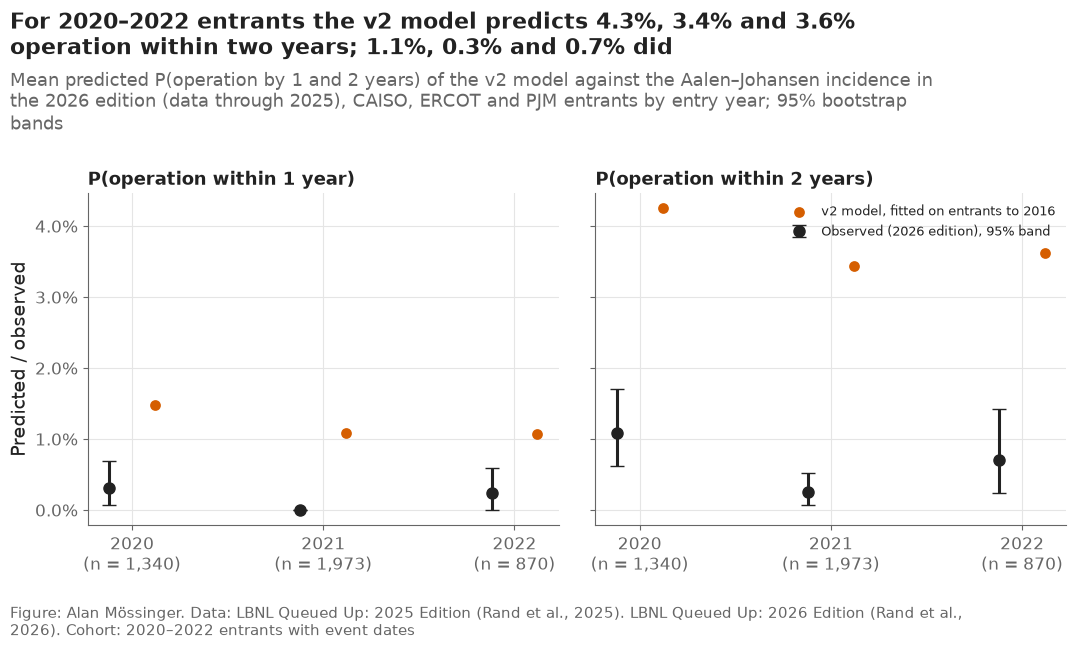

intercept that would close the 2-year gap (2025 edition outcomes): -2.15


,entry_year,horizon,edition,n_predicted,predicted,n_observed,observed,low,high,intercept_needed_2yr_2025_edition
0,2020,1,2025,1340,0.0148,1340,0.0067,0.0022,0.0112,-2.155
1,2020,1,2026,1340,0.0148,1289,0.0031,0.0008,0.0070,-2.155
2,2020,2,2025,1340,0.0425,1340,0.0127,0.0067,0.0179,-2.155
3,2020,2,2026,1340,0.0425,1289,0.0109,0.0062,0.0171,-2.155
4,2021,1,2025,1973,0.0109,1973,0.0000,0.0000,0.0000,-2.155
5,2021,1,2026,1973,0.0109,1539,0.0000,0.0000,0.0000,-2.155
6,2021,2,2025,1973,0.0344,1973,0.0010,0.0000,0.0025,-2.155
7,2021,2,2026,1973,0.0344,1539,0.0026,0.0006,0.0052,-2.155
8,2022,1,2025,870,0.0108,870,0.0000,0.0000,0.0000,-2.155
9,2022,1,2026,870,0.0108,844,0.0024,0.0000,0.0060,-2.155


In [8]:
recent = track_a[track_a["q_year"].between(2020, 2022)].copy()
p_recent = discrete_time.predict_both(fit_final, recent, horizons=[1, 2])[SPEC["model"]]
observed = pd.read_csv(paths.RESULTS / "early_incidence_2020_2022.csv")
rows = []
for year in [2020, 2021, 2022]:
    mask = (recent["q_year"] == year).to_numpy()
    for h in [1, 2]:
        for edition in [2025, 2026]:
            o = observed[(observed["entry_year"] == year) & (observed["horizon"] == h) & (observed["edition"] == edition)
                         & (observed["region"] == "CAISO+ERCOT+PJM")].iloc[0]
            rows.append({"entry_year": year, "horizon": h, "edition": edition, "n_predicted": int(mask.sum()),
                         "predicted": float(p_recent[h].to_numpy()[mask].mean()), "n_observed": int(o["n"]),
                         "observed": o["observed"], "low": o["low"], "high": o["high"]})
early_check = pd.DataFrame(rows)
# the intercept that would close the 2-year gap, from the 2025 edition's own outcomes (diagnostic only)
G_recent = evaluation.censoring_km(((pd.Timestamp(config.CENSOR_DATE) - recent["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy(),
                                   np.ones(len(recent), bool))
y2, w2 = evaluation.horizon_outcome(recent["duration_years"].to_numpy(), recent["event"].to_numpy(), 2, G_recent)
a_needed = drift.fit_intercept(p_recent[2].to_numpy(), y2, w2)
early_check["intercept_needed_2yr_2025_edition"] = a_needed
early_check.to_csv(paths.RESULTS / "early_hazards_2020_2022.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, h in zip(axes, [1, 2]):
    part = early_check[(early_check["horizon"] == h) & (early_check["edition"] == 2026)]
    x = np.arange(len(part))
    ax.errorbar(x - 0.12, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                color=plots.INK, capsize=5, markersize=8, label="Observed (2026 edition), 95% band")
    ax.scatter(x + 0.12, part["predicted"], marker="o", color="#D55E00", s=60, label="v2 model, fitted on entrants to 2016")
    ax.set_xticks(x, [f"{y}\n(n = {n:,})" for y, n in zip(part["entry_year"], part["n_predicted"])])
    ax.set_title(f"P(operation within {h} year{'s' if h > 1 else ''})", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_ylabel("Predicted / observed")
axes[1].legend(loc="upper right", fontsize=9)
ec = early_check[(early_check["horizon"] == 2) & (early_check["edition"] == 2026)].set_index("entry_year")
plots.finish(fig,
             f"For 2020–2022 entrants the v2 model predicts {ec.loc[2020, 'predicted']:.1%}, {ec.loc[2021, 'predicted']:.1%} and "
             f"{ec.loc[2022, 'predicted']:.1%} operation within two years; {ec.loc[2020, 'observed']:.1%}, "
             f"{ec.loc[2021, 'observed']:.1%} and {ec.loc[2022, 'observed']:.1%} did",
             "Mean predicted P(operation by 1 and 2 years) of the v2 model against the Aalen–Johansen incidence in the 2026 "
             "edition (data through 2025), CAISO, ERCOT and PJM entrants by entry year; 95% bootstrap bands",
             "2020–2022 entrants with event dates", lbnl_2026=True)
save(fig, "12_03_early_hazards_2020_2022", "Predicted against observed one- and two-year incidence of operation for 2020–2022 entrants.")
plt.show()
print(f"intercept that would close the 2-year gap (2025 edition outcomes): {a_needed:+.2f}")
early_check.round(4)

**Reading this.** The drift did not stop in 2019. For the 2020, 2021 and 2022 entrants the v2 model predicts 4.3%, 3.4% and 3.6% operation within two years; in the 2026 edition 1.1%, 0.3% and 0.7% did (14, 4 and 6 operations), and within one year 0.3%, 0.0% and 0.2% against 1.1–1.5% predicted. Closing the two-year gap would take an intercept of −2.16, a factor of about 0.12 on the odds — far beyond the −0.4 to −0.7 the rolling rule produced for 2018–2019. The two editions agree within their bands, so this is not a data-vintage effect. For a portfolio manager the message is blunt: a completion probability learned from the 2010s overstates what a 2020s request achieves in its first years several times over, and no entry-time model in this project is calibrated to the post-2020 queue. This is the main limitation the report carries into the portfolio layer, and the strongest reason for the landmark models of notebook 14, which condition on what has happened to a request since it entered.

## 6. Predictions for the later notebooks and checks

In [9]:
out = []
for h in config.HORIZONS:
    f = pd.DataFrame({"project_key": test["project_key"].astype(str).to_numpy(), "horizon": h,
                      "v2_raw": preds[h]["v2"], "v2_recalibrated": recal[h] if h in recal else np.nan,
                      "fair_baseline": preds[h]["fair_baseline"], "baseline": preds[h]["baseline"],
                      "region": regions, "q_year": years, "large": test["large"].to_numpy(),
                      "event": events, "duration_years": durations})
    out.append(f)
pred_level = pd.concat(out, ignore_index=True)
pred_level.to_parquet(paths.DATA_PROCESSED / "predictions_v2_recalibrated.parquet", index=False)

checks = pd.DataFrame([
    {"check": "no scored cohort is its own level source", "value": str(SOURCE_YEAR),
     "pass": all(s < y for y, s in SOURCE_YEAR.items()) and (intercepts["source_year"] < intercepts["scored_year"]).all()},
    {"check": "the refit reproduces notebook 11's predictions", "value": f"{refit_gap:.1e}", "pass": refit_gap < 1e-6},
    {"check": "recalibration leaves the ranking unchanged within each scored year and region",
     "value": int(sum(not np.array_equal(np.argsort(preds[h]["v2"][g], kind="stable"), np.argsort(recal[h][g], kind="stable"))
                      for h in LEVEL_HORIZONS for y in TEST_YEARS for r in TRACK_A
                      for g in [(years == y) & (regions == r)] if g.sum() > 1)),
     "pass": all(np.array_equal(np.argsort(preds[h]["v2"][g], kind="stable"), np.argsort(recal[h][g], kind="stable"))
                 for h in LEVEL_HORIZONS for y in TEST_YEARS for r in TRACK_A
                 for g in [(years == y) & (regions == r)] if g.sum() > 1)},
    {"check": "every level metric carries an interval", "value": int(level_metrics[["low", "high"]].isna().any(axis=1).sum()),
     "pass": not level_metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F11 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F11_level_by_entry_year.png").exists() and (paths.FIGURES / "F11_level_by_entry_year.svg").exists()},
])
checks.to_csv(paths.RESULTS / "level_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.6 min


,check,value,pass
0,no scored cohort is its own level source,"{2017: 2016, 2018: 2017, 2019: 2018}",True
1,the refit reproduces notebook 11's predictions,0.0e+00,True
2,recalibration leaves the ranking unchanged wit...,0,True
3,every level metric carries an interval,0,True
4,F11 saved as PNG and SVG,2,True


## Takeaways

- The level drifts in one direction: among requests of 20 MW and more, 5-year completion fell from 11.0% (2017 entrants) to 5.9% and 6.1% (2018, 2019); the models stayed at 12%.
- What moved is the hazard of operation in the first three years (9.1% for 2013 entrants, 2.3% for 2018–2019), not the hazard of withdrawal (24–34% to 17–23%): requests wait longer, they do not leave faster.
- The rolling recalibration (level from the cohort before, per region) removes about 40% of the 2018–2019 error (5-year intercept −0.81 → −0.47) but every option's intercept interval still excludes zero: criterion C7 fails.
- 2020–2022 entrants operate within two years at a quarter of the predicted rate (1.1%, 0.3%, 0.7% against 4.3%, 3.4%, 3.6%); closing that gap would take an intercept of −2.16.
- **What goes to the report:** F11 and figure 12_01; the C7 verdict; the limitation that no entry-time model here is calibrated to the post-2020 queue, and the handover to the landmark models.